# Neural Networks for Image Processing - Solution


**Business problem:** recognize a single scanned digit and decide what needs human review. MNIST is a benchmark,
not a representative sample of operational documents. One observation is one 28 x 28 grayscale image; the target is a digit 0-9.

In this notebook, we will:
1. Prepare image tensors without changing the official test boundary.
2. Compare a raw-pixel linear baseline with a small CNN.
3. Select a pipeline using validation cross-entropy, then evaluate fixed choices.
4. Interpret digit-level errors, review needs and limits of benchmark evidence.

**SW07 Lecture 3. Prerequisites:** neural-network training, classification and validation from Lectures 1 and 2.
One prepared-results activity fits the 10-minute lecture slot; the full sequence is a separate approximately 60-minute practical,
plus first-time downloads and model training. Do not count cold execution inside the lecture's 45 minutes.
The architecture uses two 3 x 3 convolutions (32/64 filters), pooling, dropout 0.5, Adam, batch 128 and five epochs.
Both models use final-epoch weights; validation chooses between pipelines, not between test results.


This is the completed companion to the [exercise](cnn_mnist_exercise.ipynb). Read the [concepts](cnn_mnist_concept.ipynb) first. Numbered steps, settings and code match the exercise. Try each interpretation before expanding its worked answer.

## Libraries and reproducibility

Install [the pinned PyTorch environment](../requirements-cnn-mnist-pytorch.txt) in a separate Python 3.11 environment:
`pip install -r ../requirements-cnn-mnist-pytorch.txt` from this notebook's directory.
The kernel must use that environment. Package pins describe the tested stack, not every operating system.
Neither torchvision nor TensorFlow is needed. Keep the local [MNIST reader](mnist_data.py) beside this notebook.

The reader downloads the official `mnist.npz` archive on first use, verifies its SHA-256 checksum and caches it under
`~/.cache/zhaw-ml-bi/`. Later runs can use the verified cache offline. This is separate from Lecture 4's Fashion-MNIST files.
The cell below fixes random seeds, requests deterministic PyTorch operations and uses two CPU threads.
Devices and package versions can still affect results.

In [1]:
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, log_loss, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from mnist_data import load_mnist

SEED = 7
NUM_CLASSES = 10
BATCH_SIZE = 128
EPOCHS = 5
DEVICE = torch.device('cpu')
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
print('Device:', DEVICE, '| seed:', SEED)
print({name: importlib.metadata.version(name)
       for name in ['torch', 'numpy', 'pandas', 'scikit-learn', 'matplotlib']})

Device: cpu | seed: 7
{'torch': '2.2.2', 'numpy': '1.26.4', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.9.4'}


## 1. Prepare identical images and a validation split

Use the official 60,000-image training partition. Split it into 54,000 training and 6,000 validation images with stratification
and seed 7. The loader also returns the 10,000 official test images; keep them raw and unused until Step 5.
Set `pixel_scale` to the maximum value of an 8-bit pixel, so division maps pixel values to [0, 1].
This fixed transformation learns nothing from validation or test images.

PyTorch expects images in batch x channels x height x width order: here `(N, 1, 28, 28)`.
Each target is a single integer digit from 0 to 9, stored as `torch.long`; do not one-hot encode it for this loss.
The image grid contains training examples, not examples selected for successful predictions.

Training / validation / untouched official test: 54000 6000 10000
Input shape: (1, 28, 28) | targets: (54000,) torch.int64


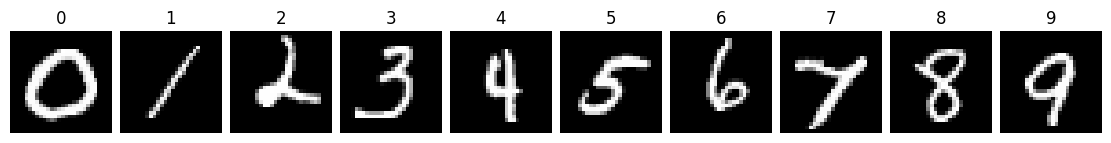

In [2]:
(raw_images, raw_labels), (raw_test_images, raw_test_labels) = load_mnist()
training_indices, validation_indices = train_test_split(
    np.arange(len(raw_labels)), test_size=6000, stratify=raw_labels, random_state=SEED
)
pixel_scale = 255.0
train_images = torch.from_numpy(raw_images[training_indices]).float().unsqueeze(1) / pixel_scale
validation_images = torch.from_numpy(raw_images[validation_indices]).float().unsqueeze(1) / pixel_scale
train_labels = raw_labels[training_indices]
validation_labels = raw_labels[validation_indices]
train_targets = torch.as_tensor(train_labels, dtype=torch.long)
validation_targets = torch.as_tensor(validation_labels, dtype=torch.long)
assert not np.intersect1d(training_indices, validation_indices).size
print('Training / validation / untouched official test:', len(train_images), len(validation_images), len(raw_test_images))
print('Input shape:', tuple(train_images.shape[1:]), '| targets:', tuple(train_targets.shape), train_targets.dtype)
figure, axes = plt.subplots(1, 10, figsize=(11, 2), layout='constrained')
for digit, axis in enumerate(axes):
    position = np.flatnonzero(train_labels == digit)[0]
    axis.imshow(train_images[position, 0], cmap='gray', vmin=0, vmax=1)
    axis.set_title(str(digit))
    axis.axis('off')
plt.show()

Why must the validation images remain outside fitting, even though division by 255 is fixed?

<details>
<summary>Answer and self-check</summary>

**Answer:** Validation estimates behavior on images not used to update weights. Fixed scaling does not remove the need for a held-out selection set. The official test partition is reserved for final evidence.

**Intermediate:** 3 points: no validation weight updates (1); validation selects pipelines (1); test remains separate (1).

**Common mistake:** Calling validation images training examples because the same normalization is applied.

</details>

## 2. Establish a business and statistical baseline

A training-majority rule always predicts the most frequent training digit. Its probability baseline uses training class proportions.
Do not assume exactly 10% accuracy: the ten digits are not perfectly balanced.
A second baseline is a trainable linear softmax model on the same 784 raw pixels. It tests whether convolutions add value.
Correct routing and reduced review workload are business outcomes; baseline accuracy is only a technical starting point.

In [3]:
prior_baseline = DummyClassifier(strategy='prior')
prior_baseline.fit(np.zeros((len(train_labels), 1)), train_labels)
prior_validation_probabilities = prior_baseline.predict_proba(np.zeros((len(validation_labels), 1)))
print('Training-majority digit:', int(prior_baseline.classes_[prior_baseline.class_prior_.argmax()]))
print('Prior validation accuracy:', accuracy_score(validation_labels, prior_validation_probabilities.argmax(axis=1)))
print('Prior validation log loss:', log_loss(validation_labels, prior_validation_probabilities, labels=np.arange(NUM_CLASSES)))

Training-majority digit: 1
Prior validation accuracy: 0.11233333333333333
Prior validation log loss: 2.301157024226629


What additional evidence does the trainable pixel baseline provide beyond guessing the training-majority digit?

<details>
<summary>Answer and self-check</summary>

**Answer:** It measures how well supervised linear combinations of the same image pixels can classify digits. CNN gains must be judged against that stronger baseline, with compute and error patterns considered as well.

**Intermediate:** 2 points: same pixel information and labels (1); stronger comparison than guessing, not equal compute (1).

**Common mistake:** Treating any improvement over roughly 10% accuracy as proof that a CNN is necessary.

</details>

## 3. Build the two pipelines

Set `kernel_size` to the height/width tuple for a 3 x 3 filter. Both convolutions use it with valid padding.
For the CNN, follow `28 -> 26 -> 13 -> 11 -> 5` in each spatial dimension. Flattening then gives 1,600 activations.
Convolutions learn shared local filters; ReLU introduces nonlinearity; pooling reduces resolution.
Dropout masks half the flattened activations in expectation during training and is inactive in ordinary prediction.

Both networks return ten raw scores (logits), not probabilities. The supplied loss consumes these logits directly;
softmax is applied separately during evaluation. The name 'Linear softmax' refers to that complete probability pipeline.
The CNN has 34,826 trainable parameters; the linear baseline has 7,850.
More parameters alone do not guarantee better generalization. A benchmark digit image is not a complete document.

In [4]:
kernel_size = (3, 3)
linear_model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, NUM_CLASSES),
)
cnn_model = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=kernel_size),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Conv2d(32, 64, kernel_size=kernel_size),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Flatten(),
    nn.Dropout(0.5),
    nn.Linear(64 * 5 * 5, NUM_CLASSES),
)
models = {'Linear softmax': linear_model, 'CNN': cnn_model}
print('Trainable parameters:', {name: sum(parameter.numel() for parameter in model.parameters())
                                for name, model in models.items()})
print(cnn_model)

Trainable parameters: {'Linear softmax': 7850, 'CNN': 34826}
Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Dropout(p=0.5, inplace=False)
  (8): Linear(in_features=1600, out_features=10, bias=True)
)


What is shared across image positions, and which of the supplied layers have no trainable parameters?

<details>
<summary>Answer and self-check</summary>

**Answer:** Each convolution reuses its filter weights and biases at different positions. Pooling, flattening and dropout add no learned weights; convolutions and `nn.Linear` do. Local responses are not causal explanations of a document decision.

**Intermediate:** 3 points: shared filter weights (1); nonparametric layers (1); no causal interpretation (1).

**Common mistake:** Assuming that flattening learns a representation or that dropout deletes units at prediction time.

</details>

## 4. Fit with a fixed budget and select on validation data

The loss is supplied: `nn.CrossEntropyLoss()`. It takes raw logits and integer digit targets, applying log-softmax internally.
Do not apply softmax before this loss. Low probability for the correct digit incurs a larger penalty.
Both models use Adam with learning rate 0.001, batch 128 and five epochs. No test images enter training or selection.
The supplied loop follows forward pass, loss, backward pass and parameter update; interpreting its output is the task here.

After each fit, find `best_validation_epoch` from `histories[name]['val_loss']`. Use `np.argmin` to locate the minimum and add 1 because array positions start at 0 but epoch numbers start at 1. If losses tie, report the first minimum.
This is a diagnostic only: identifying an earlier epoch does not restore its weights. Use final-epoch weights for the comparison and select the pipeline with the **lowest final-epoch validation log loss**.

`model.train()` activates dropout. Evaluation uses `model.eval()` to disable it and `torch.no_grad()` to disable gradient tracking.
Training loss includes active dropout; a lower validation than training loss therefore does not by itself indicate leakage.
Losses are weighted by the number of examples in each batch. Accuracy measures correct class decisions;
cross-entropy also evaluates the probability assigned to the true class.

/private/tmp/zhaw-transfer-pytorch-no-torchvision/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Linear softmax: epoch 1/5, training loss 0.6985, validation loss 0.4155


Linear softmax: epoch 2/5, training loss 0.3700, validation loss 0.3446


Linear softmax: epoch 3/5, training loss 0.3242, validation loss 0.3171


Linear softmax: epoch 4/5, training loss 0.3034, validation loss 0.3032


...

CNN: epoch 3/5, training loss 0.0881, validation loss 0.0544


CNN: epoch 4/5, training loss 0.0779, validation loss 0.0448


CNN: epoch 5/5, training loss 0.0683, validation loss 0.0451
CNN best validation-loss epoch: 4


,Validation log loss,Validation accuracy
Linear softmax,0.2949,0.9158
CNN,0.0451,0.9850


Validation-selected model: CNN


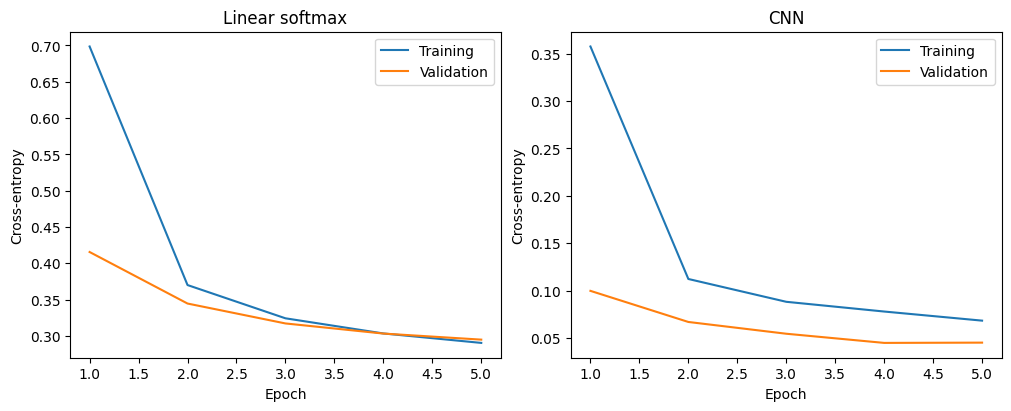

In [5]:
loss_function = nn.CrossEntropyLoss()


def evaluate_model(model, images, targets):
    model.eval()
    total_loss, total_correct = 0.0, 0
    probability_batches = []
    loader = DataLoader(TensorDataset(images, targets), batch_size=256, shuffle=False)
    with torch.no_grad():
        for batch_images, batch_targets in loader:
            batch_targets = batch_targets.to(DEVICE)
            logits = model(batch_images.to(DEVICE))
            total_loss += loss_function(logits, batch_targets).item() * len(batch_targets)
            total_correct += (logits.argmax(dim=1) == batch_targets).sum().item()
            probability_batches.append(torch.softmax(logits, dim=1).cpu().numpy())
    return total_loss / len(images), total_correct / len(images), np.concatenate(probability_batches)


histories = {}
validation_rows = {}
for name, model in models.items():
    torch.manual_seed(SEED)
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loader = DataLoader(
        TensorDataset(train_images, train_targets), batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    history = {'loss': [], 'val_loss': []}
    for epoch in range(EPOCHS):
        model.train()
        total_training_loss = 0.0
        for batch_images, batch_targets in loader:
            optimizer.zero_grad()
            logits = model(batch_images.to(DEVICE))
            loss = loss_function(logits, batch_targets.to(DEVICE))
            loss.backward()
            optimizer.step()
            total_training_loss += loss.item() * len(batch_targets)
        measured = evaluate_model(model, validation_images, validation_targets)
        history['loss'].append(total_training_loss / len(train_images))
        history['val_loss'].append(measured[0])
        print(f"{name}: epoch {epoch + 1}/{EPOCHS}, training loss {history['loss'][-1]:.4f}, validation loss {measured[0]:.4f}")
    histories[name] = history
    best_validation_epoch = int(np.argmin(histories[name]['val_loss'])) + 1
    print(name, 'best validation-loss epoch:', best_validation_epoch)
    validation_rows[name] = {'Validation log loss': measured[0], 'Validation accuracy': measured[1]}
validation_results = pd.DataFrame.from_dict(validation_rows, orient='index')
selected_model = validation_results['Validation log loss'].idxmin()
display(validation_results.round(4))
print('Validation-selected model:', selected_model)
figure, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
for axis, (name, history) in zip(axes, histories.items()):
    epoch_numbers = np.arange(1, len(history['loss']) + 1)
    axis.plot(epoch_numbers, history['loss'], label='Training')
    axis.plot(epoch_numbers, history['val_loss'], label='Validation')
    axis.set(title=name, xlabel='Epoch', ylabel='Cross-entropy')
    axis.legend()
plt.show()

Which pipeline would you select under the declared rule? Why might the best validation-loss epoch differ from the final epoch? Why is five epochs not an equal-compute comparison?

<details>
<summary>Answer and self-check</summary>

**Answer:** Select the row with minimum final-epoch validation log loss, even if the other row has slightly higher accuracy. The lowest validation-loss epoch is `int(np.argmin(histories[name]['val_loss'])) + 1`; adding 1 converts the zero-based position to an epoch number, and a tie returns the first minimum. Validation loss can rise or fluctuate as training continues, so its minimum need not occur at the final epoch. Reporting that epoch does not restore its weights: this comparison still evaluates the final-epoch models. A CNN performs more operations per example; five epochs fixes data passes, not wall time, energy or total compute.

**Intermediate:** 4 points: use the observed final-epoch validation minimum (1); distinguish accuracy from log loss (1); explain why the best epoch can differ and why reporting it does not restore weights (1); unequal compute (1).

**Common mistake:** Choosing a model from the test table, forgetting the one-based epoch number, assuming the printed epoch restores a checkpoint, or assuming more epochs must improve generalization.

</details>

## 5. Evaluate fixed choices on the official test partition

Now apply the same fixed pixel scaling to the official test images. Report accuracy and log loss for the prior rule and both models.
Keep the validation-selected pipeline regardless of test ranking. These are historical benchmark results, not a new deployment guarantee.
Do not use this test set to choose dropout, filters, epoch count or review thresholds.

In [6]:
test_images = torch.from_numpy(raw_test_images).float().unsqueeze(1) / pixel_scale
test_targets = torch.as_tensor(raw_test_labels, dtype=torch.long)
test_probabilities = {'Training prior': prior_baseline.predict_proba(np.zeros((len(raw_test_labels), 1)))}
test_probabilities.update({name: evaluate_model(model, test_images, test_targets)[2]
                           for name, model in models.items()})
test_predictions = {name: probabilities.argmax(axis=1) for name, probabilities in test_probabilities.items()}
test_results = pd.DataFrame.from_dict({name: {
    'Test accuracy': accuracy_score(raw_test_labels, test_predictions[name]),
    'Test log loss': log_loss(raw_test_labels, probabilities, labels=np.arange(NUM_CLASSES)),
} for name, probabilities in test_probabilities.items()}, orient='index')
display(test_results.round(4))
print('Validation-selected model, unchanged:', selected_model)

,Test accuracy,Test log loss
Training prior,0.1135,2.3010
Linear softmax,0.9212,0.2822
CNN,0.9865,0.0418


Validation-selected model, unchanged: CNN


How does the selected pipeline compare with both baselines? What should happen if the test ranking differs from validation?

<details>
<summary>Answer and self-check</summary>

**Answer:** Read both accuracy and log loss from the executed tables; calculate accuracy differences in percentage points. Keep the validation-selected choice. A rank reversal is uncertainty to investigate with new data, not permission to tune on this test.

**Intermediate:** 3 points: use measured results (1); percentage-point comparison (1); do not reselect on test (1).

**Common mistake:** Reporting a fabricated winning score or treating this historical comparison as independent confirmation after redesign.

</details>

## 6. Interpret errors and business consequences

Rows of the confusion matrix are true digits; columns are predicted digits. Inspect per-digit errors as well as overall accuracy.
The grid shows the first twelve test errors, or the first twelve test examples if there are none. This is explicit error inspection,
not a representative sample of all cases. Images show what happened, not why the model made a causal decision.

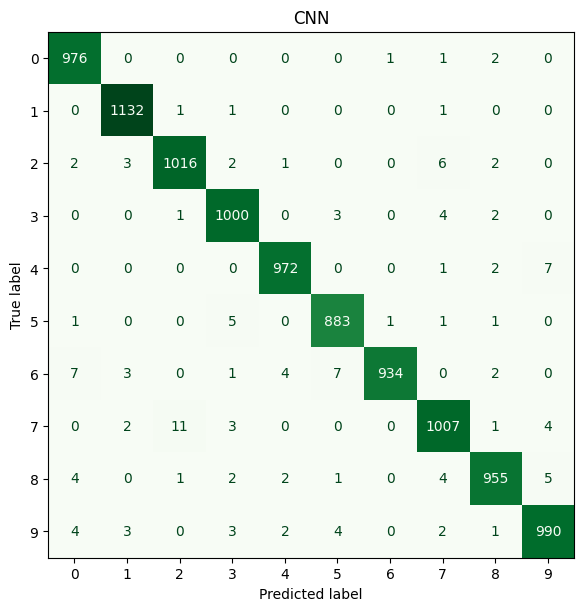

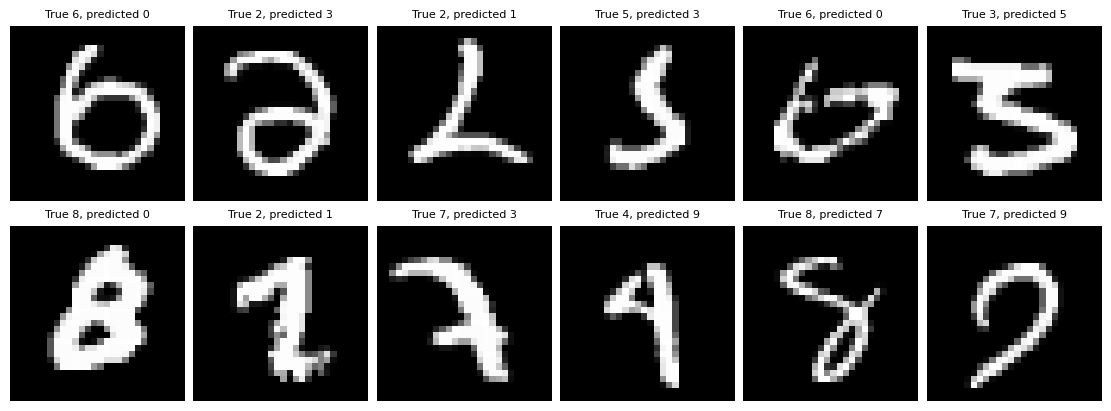

In [7]:
selected_predictions = test_predictions[selected_model]
figure, axis = plt.subplots(figsize=(7, 6), layout='constrained')
ConfusionMatrixDisplay.from_predictions(
    raw_test_labels, selected_predictions, labels=np.arange(NUM_CLASSES),
    values_format='d', colorbar=False, cmap='Greens', ax=axis
)
axis.set_title(selected_model)
plt.show()
error_positions = np.flatnonzero(selected_predictions != raw_test_labels)
positions = error_positions[:12] if len(error_positions) else np.arange(12)
figure, axes = plt.subplots(2, 6, figsize=(11, 4), layout='constrained')
for axis in axes.flat:
    axis.axis('off')
for axis, position in zip(axes.flat, positions):
    axis.imshow(raw_test_images[position], cmap='gray', vmin=0, vmax=255)
    axis.set_title(f'True {raw_test_labels[position]}, predicted {selected_predictions[position]}', fontsize=8)
plt.show()

Identify one observed digit confusion. Why could it matter more than another confusion in a document workflow?

<details>
<summary>Answer and self-check</summary>

**Answer:** Use an off-diagonal entry from the executed matrix, identify its true/predicted direction and connect it to a specified workflow cost. Equal accuracy can hide very different financial or review consequences. A digit benchmark alone supplies no monetary cost estimates.

**Intermediate:** 3 points: an actual off-diagonal observation (1); correct direction (1); explicit business assumption (1).

**Common mistake:** Claiming that the image grid explains which pixels caused a prediction or inventing financial savings.

</details>

## Business implications and limitations

MNIST digits are cropped, centered and grayscale; actual documents contain multiple characters, noise and changing capture devices.
This comparison uses one random seed and a fixed five-epoch budget. It does not optimize either architecture or isolate every source of gain.
Validation is development evidence. Repeated test inspection is not fresh confirmation.
Probability calibration, unfamiliar inputs, human review, latency, privacy and monitoring need separate evaluation.
Associations learned from pixels do not establish causal effects on business outcomes.

Would you automatically process documents with high maximum softmax probability? Specify the next evidence you need.

<details>
<summary>Answer and self-check</summary>

**Answer:** Not on this evidence alone. Evaluate representative documents under time-ordered or source-grouped separation, assess calibration and out-of-distribution failures, measure document-level error costs and review capacity, and retain a monitored human-review route.

**Intermediate:** 3 points: representative independent evidence (1); calibration and realistic costs (1); review/monitoring (1).

**Common mistake:** Treating softmax probability as a guaranteed correctness certificate.

</details>

## Summary and optional exercises

- Convolutions learn shared local patterns; flattening and a linear model provide a useful comparison.
- Train on training images, select on validation and evaluate fixed choices on the official test partition.
- Benchmark accuracy, trustworthy probabilities and business value are different claims.

**Optional practical:** predeclare one pooling or dropout change and compare using training/validation only.
**Further exercise:** test a controlled brightness or rotation shift on validation images. Do not treat this as a representative production shift.
Obtain fresh evaluation data before improving the system in response to historical test errors.

## References

**Required student reading:** James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023).
*An Introduction to Statistical Learning: With Applications in Python*. Springer. Neural-network material.
https://www.statlearning.com/

**Dataset:** LeCun, Y., Cortes, C., & Burges, C. J. C. *The MNIST Database of Handwritten Digits*.
https://yann.lecun.com/exdb/mnist/
The local [MNIST reader](mnist_data.py) downloads the [official archive](https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz)
with NumPy and the Python standard library; it does not import TensorFlow or torchvision.

**Official technical documentation:** PyTorch
[Conv2d](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html),
[MaxPool2d](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html),
[Dropout](https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html),
[CrossEntropyLoss](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html).

**Optional reading:** Zhang, A., Lipton, Z. C., Li, M., & Smola, A. J.
*Dive into Deep Learning*. Convolutional neural networks. https://d2l.ai/

**Environment:** [Pinned PyTorch CNN requirements](../requirements-cnn-mnist-pytorch.txt).
Use the matching Python 3.11 kernel and keep `mnist_data.py` beside the notebooks.
Neither torchvision nor TensorFlow is required.

### Jupyter notebook - footer info

Include this information when submitting your notebook.

In [8]:
import platform
from datetime import datetime

print(platform.platform())
print('Python:', platform.python_version())
print('Date:', datetime.now().isoformat(timespec='seconds'))

macOS-26.6.2-arm64-i386-64bit
Python: 3.11.11
Date: 2026-10-25T23:05:49
